# P3.02 — Are municipal IMI rate cuts capitalised into prices? Event study and dose-response

**Questions:** RQ7.4 (how much of a cut passes into higher prices rather than lower housing costs) and M3 (which
relationships have a credible identification strategy).

**Design** (fixed in `reports/p3_policy.md` before estimating): treated municipalities are those with an
*isolated* cut of the urban IMI rate (no other change from two years before to one year after); controls are
municipalities whose rate did not change from two years before to two years after, compared **within the same
NUTS 3 region and year**. One stack per event year, 2018 to 2023 (prices start in 2016, so the 2016 wave has no
pre-period). Outcome: real price per m² (log). The coefficient on "years since the cut" *k* is the price of
treated municipalities relative to controls, against the year before the cut (*k* = −1). The two years before
the cut (*k* = −2) are the pre-trend test.

**Decision rules (fixed in advance):** pre-trend coefficients jointly significant at 10% → report as an adjusted
association; interval contains both zero and full capitalisation → inconclusive; interval excludes full
capitalisation → phase 4 uses the interval.

**Benchmark:** a permanent cut of 0.01 pp, fully capitalised, raises the price by (cut × assessed value / price) /
discount rate; with the ranges of `config/scenarios.yaml` that is the line drawn in the figure.

In [1]:
import numpy as np
import pandas as pd
import yaml

from pthousing.analysis import causal
from pthousing.analysis import panel as pn
from pthousing.config import SCENARIOS_YAML
from pthousing.data import build_panel
from pthousing.viz import charts, style

style.apply_style()
frame = causal.build_frame(build_panel.read("panel_municipality_year"))
mainland = frame[frame["territory"] == "continente"]

bench = yaml.safe_load(SCENARIOS_YAML.read_text(encoding="utf-8"))["imi_capitalisation_benchmark"]
tv, dr = bench["tax_value_ratio"], bench["discount_rate"]
full = {
    "low": causal.full_capitalisation_pct(0.01, tv["low"], dr["high"]),
    "mid": causal.full_capitalisation_pct(0.01, tv["mid"], dr["mid"]),
    "high": causal.full_capitalisation_pct(0.01, tv["high"], dr["low"]),
}
print(
    {k: round(v, 3) for k, v in full.items()}, "% price effect of a fully capitalised 0.01 pp cut"
)

{'low': 0.1, 'mid': 0.188, 'high': 0.333} % price effect of a fully capitalised 0.01 pp cut


## Step 1 — Stacked event study
Coefficients are in % of the price per 0.01 pp of cut (dose version) or per cut of any size (binary version).
The orange points are the check: the same comparison estimated cohort by cohort (a 2×2 difference per event
year, treated against controls of the same region) and averaged, with a bootstrap over municipalities. It does not
pool cohorts in one regression, so it is not affected by the way effects might differ between event years.

In [2]:
stacks = causal.build_stacks(mainland)
print(
    stacks.groupby("stack")
    .agg(treated=("treated", lambda s: s.sum() // 5), units=("unit", "nunique"))
    .assign(controls=lambda d: d["units"] - d["treated"])
    .T
)
results = {}
for label, dose in (("dose", True), ("binary", False)):
    es = causal.event_study(stacks, dose=dose)
    cohort = causal.cohort_did(stacks, dose=dose, n_boot=500)
    results[label] = (es, cohort)
    print(
        label,
        "pre-trend p =",
        round(es.pretrend_p, 3),
        "| treated",
        es.n_treated,
        "controls",
        es.n_controls,
    )

stack     2018  2019  2020  2021  2022  2023
treated      9     3    30     4     5    14
units      114   118   150   133   135   172
controls   105   115   120   129   130   158


dose pre-trend p = 0.024 | treated 65 controls 757


binary pre-trend p = 0.061 | treated 65 controls 757


In [3]:
rows = []
for label, (es, cohort) in results.items():
    rows.append(es.table.assign(estimator="stacked regression", version=label))
    rows.append(
        cohort.drop(columns="n_cohorts").assign(estimator="cohort 2x2", version=label, p=np.nan)
    )
table = pd.concat(rows, ignore_index=True)
for col in ("coef", "se", "ci_low", "ci_high"):
    table[col + "_pct"] = 100 * table[col]
style.save_table(table.round(4), "p3", "event_study_main")
table[["version", "estimator", "k", "coef_pct", "se_pct", "ci_low_pct", "ci_high_pct"]].round(2)

,version,estimator,k,coef_pct,se_pct,ci_low_pct,ci_high_pct
0,dose,stacked regression,-2,-1.51,0.67,-2.83,-0.20
1,dose,stacked regression,0,-0.67,1.06,-2.74,1.41
2,dose,stacked regression,1,-0.24,0.81,-1.83,1.35
3,dose,stacked regression,2,-0.81,1.39,-3.54,1.92
4,dose,cohort 2x2,-2,-1.23,0.74,-2.75,0.05
5,dose,cohort 2x2,0,-0.23,1.02,-1.88,1.89
6,dose,cohort 2x2,1,0.53,1.02,-1.24,2.76
7,dose,cohort 2x2,2,-0.21,1.25,-2.08,2.76
8,binary,stacked regression,-2,-4.24,2.27,-8.69,0.20
9,binary,stacked regression,0,1.61,2.61,-3.50,6.73


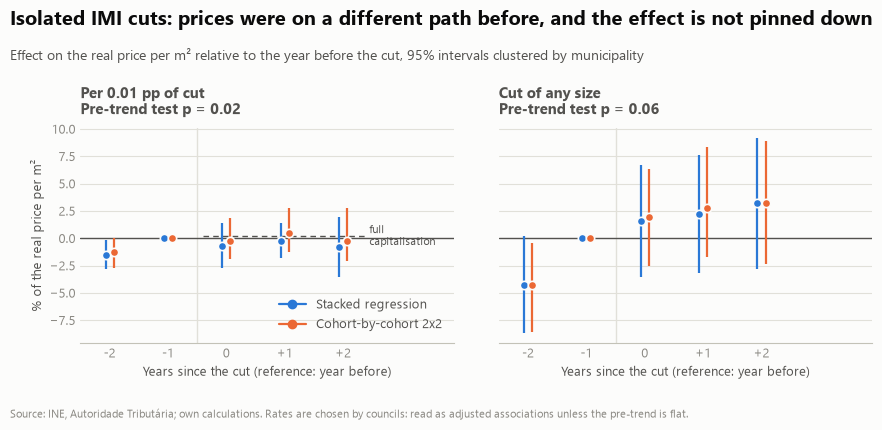

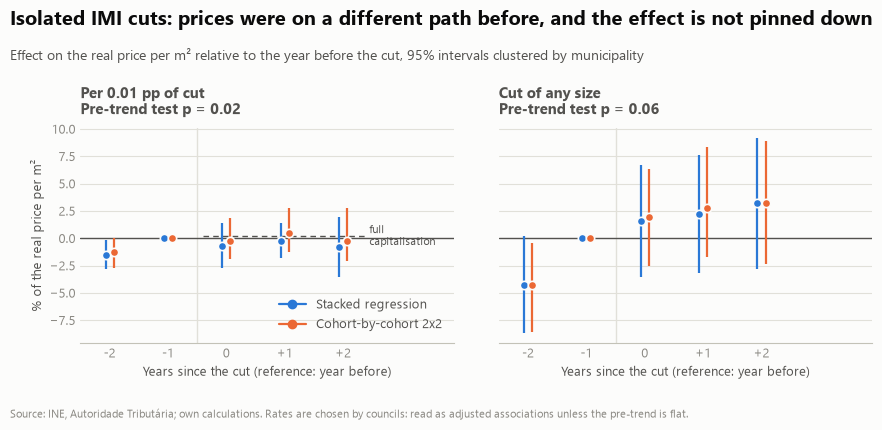

In [4]:
dose_es, dose_cohort = results["dose"]
bin_es, bin_cohort = results["binary"]
fig = charts.event_study_plot(
    [
        {
            "title": "Per 0.01 pp of cut",
            "table": dose_es.table,
            "compare": dose_cohort,
            "pretrend_p": dose_es.pretrend_p,
            "benchmark": full["mid"],
            "headline": "Isolated IMI cuts: prices were on a different path before, and the effect is not pinned down",
        },
        {
            "title": "Cut of any size",
            "table": bin_es.table,
            "compare": bin_cohort,
            "pretrend_p": bin_es.pretrend_p,
        },
    ],
    unit="% of the real price per m²",
)
style.save_fig(fig, "p3", "event_study_main")
fig

## Step 2 — Apply the decision rules

In [5]:
t = dose_es.table.set_index("k")
summary = pd.DataFrame(
    {
        "quantity": [
            "pre-trend test (k = -2), p",
            "k = -2 coefficient (% per 0.01 pp)",
            "k = +1 (% per 0.01 pp)",
            "k = +2 (% per 0.01 pp)",
            "full capitalisation, low / mid / high (% per 0.01 pp)",
        ],
        "value": [
            f"{dose_es.pretrend_p:.3f}",
            f"{100 * t.loc[-2, 'coef']:+.2f}",
            f"{100 * t.loc[1, 'coef']:+.2f}  [{100 * t.loc[1, 'ci_low']:+.2f}, {100 * t.loc[1, 'ci_high']:+.2f}]",
            f"{100 * t.loc[2, 'coef']:+.2f}  [{100 * t.loc[2, 'ci_low']:+.2f}, {100 * t.loc[2, 'ci_high']:+.2f}]",
            f"{full['low']:.2f} / {full['mid']:.2f} / {full['high']:.2f}",
        ],
    }
)
style.save_table(summary, "p3", "event_study_decision")
summary

,quantity,value
0,"pre-trend test (k = -2), p",0.024
1,k = -2 coefficient (% per 0.01 pp),-1.51
2,k = +1 (% per 0.01 pp),"-0.24 [-1.83, +1.35]"
3,k = +2 (% per 0.01 pp),"-0.81 [-3.54, +1.92]"
4,"full capitalisation, low / mid / high (% per 0...",0.10 / 0.19 / 0.33


In [6]:
rule_pre = dose_es.pretrend_p < 0.10
contains_zero = t.loc[1, "ci_low"] < 0 < t.loc[1, "ci_high"]
contains_full = t.loc[1, "ci_low"] * 100 < full["mid"] < t.loc[1, "ci_high"] * 100
print("pre-trend rejected at 10%:", rule_pre)
print(
    "k = +1 interval contains zero:",
    contains_zero,
    "and the mid full-capitalisation benchmark:",
    contains_full,
)

pre-trend rejected at 10%: True
k = +1 interval contains zero: True and the mid full-capitalisation benchmark: True


**Reading.** The rule on pre-trends applies first: if it is rejected, the post-cut coefficients are adjusted
associations whatever their size. The second rule needs the interval at *k* = +1 and +2 (above) against the
benchmark band.

## Step 3 — Dose-response with all rate changes
Annual change of the log real price on the size of the cut this year and last year (in 0.01 pp), with
municipality and NUTS 3 × year effects, errors clustered by municipality, 2016 to 2025. This uses every change,
not only isolated ones (303 cuts plus the increases), but is exposed to the staggered-timing problem, so it is
the second estimate. Variants: add last year's price growth (cuts may follow booms), and add *future* cuts as a
placebo (a cut in *t*+1 or *t*+2 cannot cause this year's price growth).

In [7]:
variants = {
    "cut this year and last": dict(lags=(0, 1)),
    "+ last year's price growth": dict(lags=(0, 1), controls=("d_log_price_l1",)),
    "placebo: future cuts": dict(lags=(0, 1), leads=(1, 2)),
}
dose_tables = []
for label, kw in variants.items():
    res = causal.dose_response(mainland, **kw)
    ct = pn.coef_table(res, label)
    cum = causal.cumulative(res, ["cut_l0", "cut_l1"])
    ct["cum_l0_l1"], ct["cum_se"] = cum["coef"], cum["se"]
    dose_tables.append(ct)
dose_table = pd.concat(dose_tables, ignore_index=True)
for col in ("coef", "se", "ci_low", "ci_high", "cum_l0_l1", "cum_se"):
    dose_table[col + "_pct"] = 100 * dose_table[col]
style.save_table(dose_table.round(4), "p3", "dose_response")
dose_table[
    ["spec", "term", "coef_pct", "se_pct", "p", "cum_l0_l1_pct", "cum_se_pct", "n_obs", "n_munis"]
].round(3)

,spec,term,coef_pct,se_pct,p,cum_l0_l1_pct,cum_se_pct,n_obs,n_munis
0,cut this year and last,cut_l0,0.243,0.388,0.531,0.382,0.385,2309,274
1,cut this year and last,cut_l1,0.139,0.273,0.610,0.382,0.385,2309,274
2,+ last year's price growth,cut_l0,0.071,0.386,0.855,0.226,0.482,2027,273
3,+ last year's price growth,cut_l1,0.155,0.265,0.558,0.226,0.482,2027,273
4,+ last year's price growth,d_log_price_l1,-49.886,2.790,0.000,0.226,0.482,2027,273
5,placebo: future cuts,cut_l0,0.345,0.455,0.448,0.784,0.447,1757,271
6,placebo: future cuts,cut_l1,0.439,0.310,0.157,0.784,0.447,1757,271
7,placebo: future cuts,cut_f1,0.452,0.388,0.244,0.784,0.447,1757,271
8,placebo: future cuts,cut_f2,-0.619,0.500,0.216,0.784,0.447,1757,271


## What this says
See the summary table and the figure; the interpretation (and the robustness checks, power and what is
passed on to phase 4) is in `p3_03` and `reports/p3_policy.md`.